<a href="https://colab.research.google.com/github/yolohe1210/cse450/blob/main/module4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
# Import the libraries we need
# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

In [40]:
url = 'https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv'
bikes = pd.read_csv(url)

bikes.head()

,dteday,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
0,1/1/2011,0.0,3,13,3.0,3.0,0.7957,0.8,1,1,0,0
1,1/1/2011,1.0,8,30,1.7,1.7,0.8272,0.8,1,1,0,0
2,1/1/2011,2.0,5,26,1.9,1.9,0.8157,1.1,1,1,0,0
3,1/1/2011,3.0,3,9,2.5,2.5,0.7831,0.8,1,1,0,0
4,1/1/2011,4.0,0,1,2.0,2.0,0.8075,1.1,1,1,0,0


In [41]:
bikes.describe()

,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
count,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000,112475.000000
mean,11.501098,90.434612,249.193625,15.376487,14.659325,0.636624,13.100614,1.405441,2.495799,0.030300,0.684312
std,6.921864,128.655621,258.267544,9.749467,11.428324,0.190328,7.857600,0.683450,1.101152,0.171412,0.464791
min,0.000000,0.000000,0.000000,-14.700000,-24.000000,0.088900,0.000000,1.000000,1.000000,0.000000,0.000000
25%,6.000000,7.000000,48.000000,7.600000,5.400000,0.484100,7.700000,1.000000,2.000000,0.000000,0.000000
50%,12.000000,36.000000,180.000000,16.000000,16.000000,0.640900,12.200000,1.000000,2.000000,0.000000,1.000000
75%,18.000000,122.000000,360.000000,23.500000,23.500000,0.798800,17.500000,2.000000,3.000000,0.000000,1.000000
max,23.000000,1244.000000,1702.000000,40.500000,49.600000,1.000000,69.800000,4.000000,4.000000,1.000000,1.000000


In [42]:
print(bikes.columns)

Index(['dteday', 'hr', 'casual', 'registered', 'temp_c', 'feels_like_c', 'hum',
       'windspeed', 'weathersit', 'season', 'holiday', 'workingday'],
      dtype='object')


In [43]:
y = bikes['casual'] + bikes['registered']

cols_to_drop = ['dteday', 'casual', 'registered', 'cnt']

cols_to_drop = [col for col in cols_to_drop if col in bikes.columns]

X = bikes.drop(columns=cols_to_drop)

print("Columns:", bikes.columns.tolist())
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(X.head())

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

print(X.head())

Columns: ['dteday', 'hr', 'casual', 'registered', 'temp_c', 'feels_like_c', 'hum', 'windspeed', 'weathersit', 'season', 'holiday', 'workingday']
X shape: (112475, 9)
y shape: (112475,)
    hr  temp_c  feels_like_c     hum  windspeed  weathersit  season  holiday  \
0  0.0     3.0           3.0  0.7957        0.8           1       1        0   
1  1.0     1.7           1.7  0.8272        0.8           1       1        0   
2  2.0     1.9           1.9  0.8157        1.1           1       1        0   
3  3.0     2.5           2.5  0.7831        0.8           1       1        0   
4  4.0     2.0           2.0  0.8075        1.1           1       1        0   

   workingday  
0           0  
1           0  
2           0  
3           0  
4           0  
X shape: (112475, 9)
y shape: (112475,)
    hr  temp_c  feels_like_c     hum  windspeed  weathersit  season  holiday  \
0  0.0     3.0           3.0  0.7957        0.8           1       1        0   
1  1.0     1.7           1.7  0.8272  

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

norm = MinMaxScaler().fit(X_train)

X_train = norm.transform(X_train)
X_test = norm.transform(X_test)

In [45]:
model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,649 (45.50 KB)

 Trainable params: 11,649 (45.50 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae", "mse"]
)

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    validation_split=0.2,
    batch_size=64,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6
        )
    ],
    shuffle=True,
    verbose=2
)

hist = pd.DataFrame(history.history)
hist = hist.reset_index()

Epoch 1/200
985/985 - 4s - 5ms/step - loss: 94521.1719 - mae: 223.1063 - mse: 94521.1719 - val_loss: 73813.0703 - val_mae: 196.9166 - val_mse: 73813.0703 - learning_rate: 0.0010
Epoch 2/200
985/985 - 2s - 2ms/step - loss: 70458.9375 - mae: 188.8777 - mse: 70458.9375 - val_loss: 64248.5352 - val_mae: 175.2079 - val_mse: 64248.5352 - learning_rate: 0.0010
Epoch 3/200
985/985 - 2s - 2ms/step - loss: 60146.9375 - mae: 170.0568 - mse: 60146.9375 - val_loss: 55557.9492 - val_mae: 166.2880 - val_mse: 55557.9492 - learning_rate: 0.0010
Epoch 4/200
985/985 - 2s - 2ms/step - loss: 53511.7422 - mae: 157.5604 - mse: 53511.7422 - val_loss: 50864.8711 - val_mae: 150.8238 - val_mse: 50864.8711 - learning_rate: 0.0010
Epoch 5/200
985/985 - 3s - 3ms/step - loss: 50067.3906 - mae: 150.1798 - mse: 50067.3906 - val_loss: 49501.0781 - val_mae: 143.4357 - val_mse: 49501.0781 - learning_rate: 0.0010
Epoch 6/200
985/985 - 3s - 3ms/step - loss: 47993.6562 - mae: 145.3062 - mse: 47993.6562 - val_loss: 46725.113

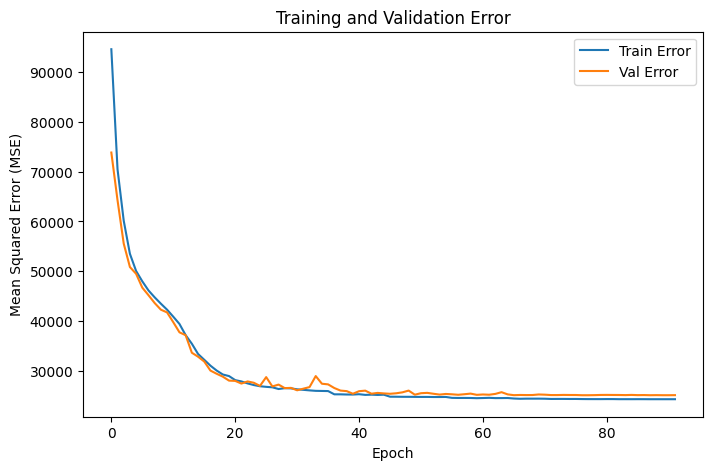

In [47]:
def plot_history():
    plt.figure(figsize=(8, 5))
    plt.xlabel('Epoch')
    plt.ylabel('Mean Squared Error (MSE)')
    plt.plot(hist['index'], hist['mse'], label='Train Error')
    plt.plot(hist['index'], hist['val_mse'], label='Val Error')
    plt.legend()
    plt.title('Training and Validation Error')
    plt.show()

plot_history()

In [48]:
predictions = model.predict(X_test).flatten()
predictions = np.maximum(predictions, 0)

rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Test RMSE: {rmse:.2f}")
print(f"Test R^2 Score: {r2:.4f}")

1055/1055 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Test RMSE: 157.91
Test R^2 Score: 0.7892


In [49]:
december_url = 'https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes_december.csv'
december = pd.read_csv(december_url)

X_december = december.drop(columns=['dteday'])

X_december = X_december[X.columns]

X_december_scaled = norm.transform(X_december)

december_predictions = model.predict(X_december_scaled).flatten()

december_predictions = np.maximum(0, np.round(december_predictions)).astype(int)

submission = december[['dteday', 'hr']].copy()
submission['cnt'] = december_predictions

submission.to_csv('bikes_december_predictions.csv', index=False)
submission.head()


46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,dteday,hr,cnt
0,11/1/2023,0.0,33
1,11/1/2023,1.0,24
2,11/1/2023,2.0,12
3,11/1/2023,3.0,8
4,11/1/2023,4.0,16


In [50]:
holdout_url = "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes_december.csv"
holdout_data = pd.read_csv(holdout_url)

X_holdout = holdout_data.drop(
    columns=['dteday', 'casual', 'registered', 'cnt'],
    errors='ignore'
)

X_holdout = X_holdout[X.columns]

X_holdout_scaled = norm.transform(X_holdout)

raw_predictions = model.predict(X_holdout_scaled).flatten()
raw_predictions = np.maximum(raw_predictions, 0)

submission_df = pd.DataFrame({
    'predictions': raw_predictions
})

print(submission_df.head())
print(submission_df.describe())
print("Rows:", len(submission_df))
print("Missing values:", submission_df.isna().sum().sum())

file_name = 'team2-module4-predictions.csv'
submission_df.to_csv(file_name, index=False)

print(f"File generated: {file_name}")

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
   predictions
0    32.766560
1    24.208797
2    12.217257
3     8.206035
4    15.928733
       predictions
count  1465.000000
mean    276.506622
std     241.859924
min       0.000000
25%      64.231155
50%     227.862961
75%     421.719879
max    1262.604858
Rows: 1465
Missing values: 0
File generated: team2-module4-predictions.csv
